In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

In [13]:
uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore (1).csv


In [14]:
file_name = next(iter(uploaded))

df = pd.read_csv(file_name, encoding="latin1")

print("Dataset shape:", df.shape)
display(df.head())

df.info()

Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [15]:
# Check data quality before cleaning
print("Rows before cleaning:", len(df))
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Clean column names
df.columns = df.columns.str.strip()

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Convert date columns
for col in ["Order Date", "Ship Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")

# Convert numeric columns
numeric_cols = ["Sales", "Profit", "Quantity", "Discount"]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nRows after cleaning:", len(df))

print("\nMissing values after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDate data types:")
print(df[["Order Date", "Ship Date"]].dtypes)

display(df.head())

Rows before cleaning: 9994
Duplicate rows: 0

Missing values:
Series([], dtype: int64)

Rows after cleaning: 9994

Missing values after cleaning:
Series([], dtype: int64)

Date data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [16]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

summary = pd.DataFrame({
    "Metric": [
        "Total Sales",
        "Total Profit",
        "Distinct Orders",
        "Unique Customers",
        "Profit Margin (%)"
    ],
    "Value": [
        round(total_sales, 2),
        round(total_profit, 2),
        total_orders,
        total_customers,
        round(profit_margin, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Sales,2297200.86
1,Total Profit,286397.02
2,Distinct Orders,5009.00
3,Unique Customers,793.00
4,Profit Margin (%),12.47


In [17]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
      .round(2)
)

display(category_analysis)

print(
    "Highest-sales category:",
    category_analysis["Sales"].idxmax()
)

print(
    "Most-profitable category:",
    category_analysis["Profit"].idxmax()
)

,Sales,Profit,Quantity
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


Highest-sales category: Technology
Most-profitable category: Technology


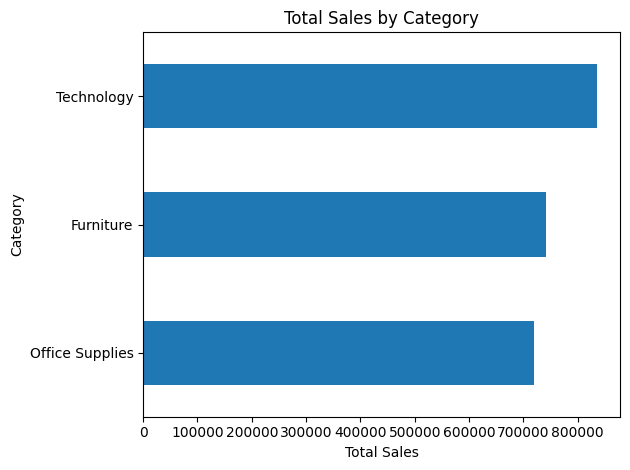

In [18]:
category_analysis["Sales"].sort_values().plot(
    kind="barh",
    title="Total Sales by Category",
    xlabel="Total Sales",
    ylabel="Category"
)

plt.tight_layout()
plt.show()

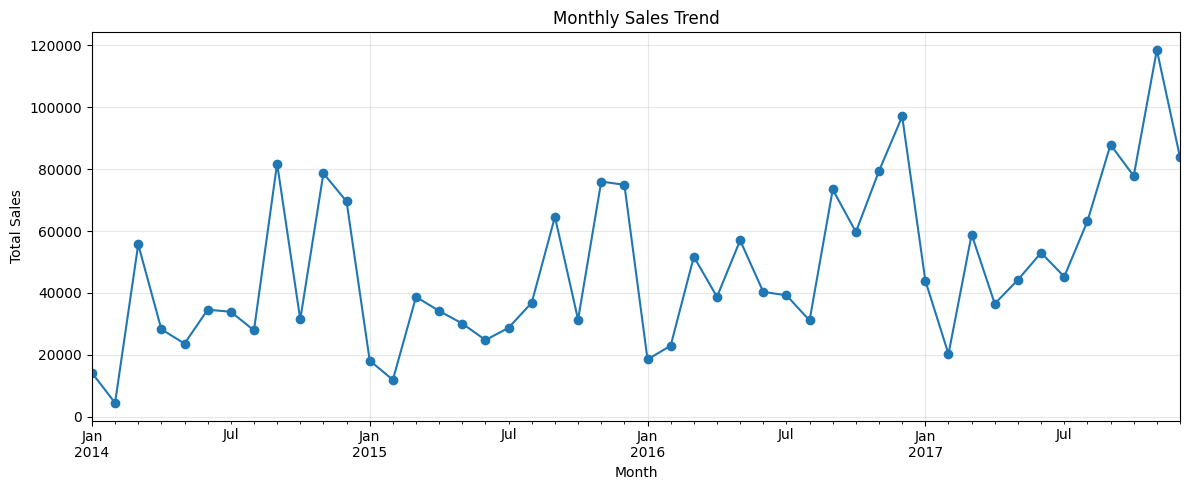

,Sales
Order Date,
2014-01-01,14236.90
2014-02-01,4519.89
2014-03-01,55691.01
2014-04-01,28295.34
2014-05-01,23648.29
2014-06-01,34595.13
2014-07-01,33946.39
2014-08-01,27909.47
2014-09-01,81777.35


In [19]:
monthly_sales = (
    df.set_index("Order Date")
      .resample("MS")["Sales"]
      .sum()
)

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o",
    title="Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales.to_frame(name="Sales").round(2))

In [20]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
      .round(2)
)

display(region_analysis)

print(
    "Highest-sales region:",
    region_analysis["Sales"].idxmax()
)

print(
    "Most-profitable region:",
    region_analysis["Profit"].idxmax()
)

,Sales,Profit,Quantity
Region,,,
West,725457.82,108418.45,12266
East,678781.24,91522.78,10618
Central,501239.89,39706.36,8780
South,391721.90,46749.43,6209


Highest-sales region: West
Most-profitable region: West


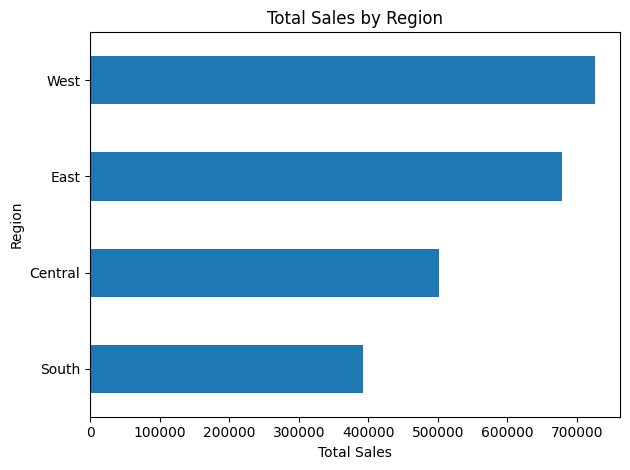

In [21]:
region_analysis["Sales"].sort_values().plot(
    kind="barh",
    title="Total Sales by Region",
    xlabel="Total Sales",
    ylabel="Region"
)

plt.tight_layout()
plt.show()

In [22]:
discount_analysis = (
    df.groupby("Discount")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Order_Lines=("Discount", "size")
      )
      .sort_index()
      .round(2)
)

display(discount_analysis)

print("\nDiscount levels with negative total profit:")
display(discount_analysis[discount_analysis["Profit"] < 0])

,Sales,Profit,Order_Lines
Discount,,,
0.00,1087908.47,320987.60,4798
0.10,54369.35,9029.18,94
0.15,27558.52,1418.99,52
0.20,764594.37,90337.31,3657
0.30,103226.66,-10369.28,227
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,206
0.45,5484.97,-2493.11,11
0.50,58918.54,-20506.43,66



Discount levels with negative total profit:


,Sales,Profit,Order_Lines
Discount,,,
0.30,103226.66,-10369.28,227
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,206
0.45,5484.97,-2493.11,11
0.50,58918.54,-20506.43,66
0.60,6644.70,-5944.66,138
0.70,40620.28,-40075.36,418
0.80,16963.76,-30539.04,300


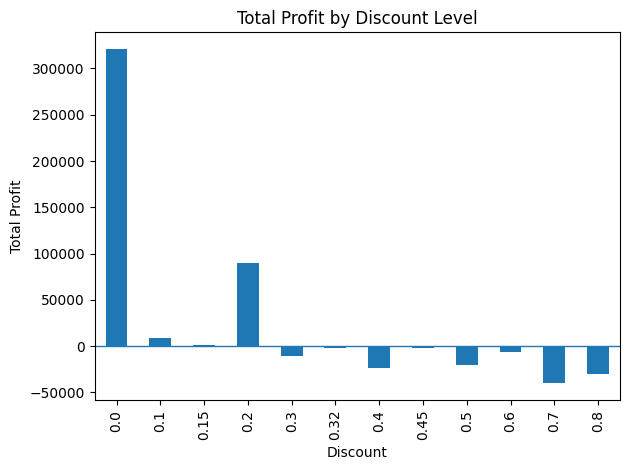

In [23]:
discount_analysis["Profit"].plot(
    kind="bar",
    title="Total Profit by Discount Level",
    xlabel="Discount",
    ylabel="Total Profit"
)

plt.axhline(y=0, linewidth=1)
plt.tight_layout()
plt.show()

In [24]:
top_products = (
    df.groupby("Product Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Sales", ascending=False)
      .head(10)
      .round(2)
)

display(top_products)

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27


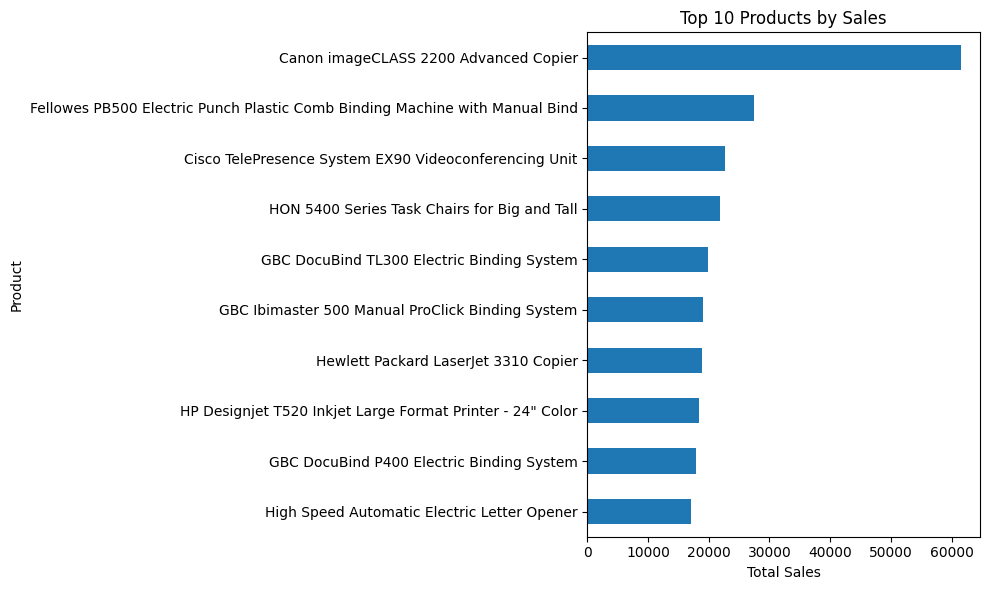

In [25]:
top_products["Sales"].sort_values().plot(
    kind="barh",
    title="Top 10 Products by Sales",
    xlabel="Total Sales",
    ylabel="Product",
    figsize=(10, 6)
)

plt.tight_layout()
plt.show()

In [27]:
top_profit_products = (
    df.groupby("Product Name")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Quantity=("Quantity", "sum")
      )
      .sort_values("Profit", ascending=False)
      .head(10)
      .round(2)
)

display(top_profit_products)

,Sales,Profit,Quantity
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
Canon PC1060 Personal Laser Copier,11619.83,4570.93,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.29,3696.28,24
Ibico EPK-21 Electric Binding System,15875.92,3345.28,13


In [ ]:
output_file = "superstore_cleaned.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved as:", output_file)

files.download(output_file)